[*********************100%***********************]  4 of 4 completed


RF vol MAE: 0.00390 | naive MAE: 0.00354

Model                       Breach rate  Kupiec LR  p-value  Avg CVaR
ML + Monte Carlo                  4.47%       0.54    0.462     2.05%
Naive vol + Monte Carlo           6.19%       2.41    0.121     1.90%
(p > 0.05 => cannot reject correct VaR coverage)


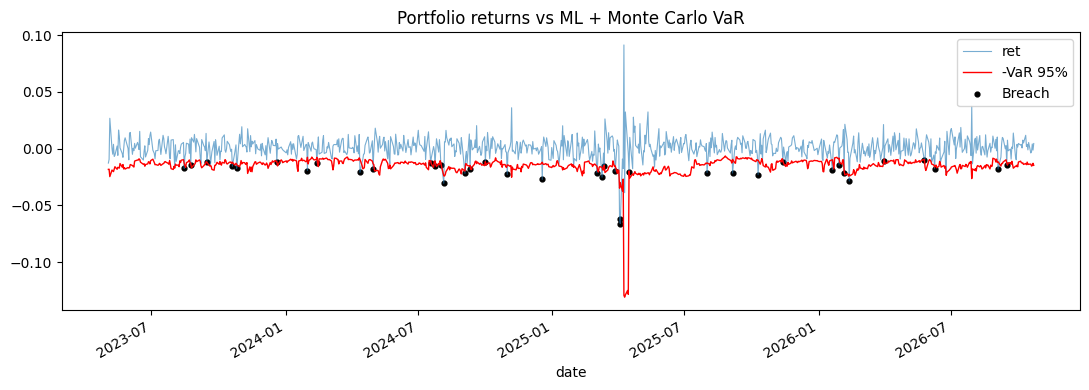

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import chi2
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

TICKERS = ["AAPL", "MSFT", "JPM", "XOM"]
WEIGHTS = np.ones(len(TICKERS)) / len(TICKERS)
N_SIMS, ALPHA, T_DF, TRAIN_FRAC = 5_000, 0.05, 5, 0.7
rng = np.random.default_rng(42)


def load_data():
    px = yf.download(TICKERS, start="2015-01-01", auto_adjust=True)["Close"].dropna()
    rets = np.log(px / px.shift(1)).dropna()
    return rets, rets @ WEIGHTS


def build_dataset(port):
    X = pd.DataFrame({
        "ret_lag1": port.shift(1), "ret_lag2": port.shift(2), "abs_ret": port.abs(),
        "vol_5": port.rolling(5).std(), "vol_21": port.rolling(21).std(),
        "vol_63": port.rolling(63).std(),
    })
    y = port.rolling(5).std().shift(-5).rename("y")
    d = pd.concat([X, y], axis=1).dropna()
    return d.drop(columns="y"), d["y"]


def mc_var(vol_forecast, chol):
    z = rng.standard_t(T_DF, (N_SIMS, chol.shape[0])) / np.sqrt(T_DF / (T_DF - 2))
    sim = (z @ chol.T) @ WEIGHTS
    sim = sim / sim.std() * vol_forecast
    var = -np.quantile(sim, ALPHA)
    cvar = -sim[sim <= -var].mean()
    return var, cvar


def backtest(vols, port, chol):
    rows = [(d, *mc_var(v, chol), port.loc[d]) for d, v in vols.items()]
    bt = pd.DataFrame(rows, columns=["date", "VaR", "CVaR", "ret"]).set_index("date")
    bt["breach"] = -bt["ret"] > bt["VaR"]
    return bt


def kupiec(breaches, p=ALPHA):
    T, x = len(breaches), int(breaches.sum())
    ph = x / T
    ll0 = (T - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (T - x) * np.log(1 - ph) + x * np.log(ph) if 0 < x < T else 0.0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - chi2.cdf(lr, 1)


def main():
    rets, port = load_data()
    X, y = build_dataset(port)
    split = int(len(X) * TRAIN_FRAC)
    X_tr, X_te, y_tr, y_te = X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]

    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                  random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    ml_vol = pd.Series(model.predict(X_te), index=X_te.index)
    naive_vol = port.rolling(21).std().shift(1).reindex(X_te.index)
    naive_vol = naive_vol.fillna(naive_vol.mean())

    print(f"RF vol MAE: {mean_absolute_error(y_te, ml_vol):.5f} | "
          f"naive MAE: {mean_absolute_error(y_te, naive_vol):.5f}")

    chol = np.linalg.cholesky(rets.iloc[:split].corr().values)
    results = {"ML + Monte Carlo": backtest(ml_vol, port, chol),
               "Naive vol + Monte Carlo": backtest(naive_vol, port, chol)}

    print(f"\n{'Model':26s}{'Breach rate':>13s}{'Kupiec LR':>11s}{'p-value':>9s}{'Avg CVaR':>10s}")
    for name, bt in results.items():
        lr, p = kupiec(bt["breach"])
        print(f"{name:26s}{bt['breach'].mean():>13.2%}{lr:>11.2f}{p:>9.3f}{bt['CVaR'].mean():>10.2%}")
    print("(p > 0.05 => cannot reject correct VaR coverage)")

    bt = results["ML + Monte Carlo"]
    ax = bt[["ret"]].plot(figsize=(11, 4), alpha=0.6, lw=0.8)
    (-bt["VaR"]).plot(ax=ax, color="red", lw=1, label="-VaR 95%")
    ax.scatter(bt.index[bt["breach"]], bt["ret"][bt["breach"]], c="k", s=12, label="Breach")
    ax.legend(); ax.set_title("Portfolio returns vs ML + Monte Carlo VaR")
    plt.tight_layout(); plt.savefig("var_backtest.png", dpi=150)


if __name__ == "__main__":
    main()